In [137]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv("customers_clean.csv")
sales = pd.read_csv("sales_clean.csv", low_memory=False)
items = pd.read_csv("items_clean.csv")
df = sales.merge(customers, on="customer_id", how="left")
df = df.merge(items, on="item_id", how="left")

# 1. Customer Age Distribution

age_band
25-34    5279
35-44    3295
18-24    2953
45-54    1758
55+       879
Name: count, dtype: int64


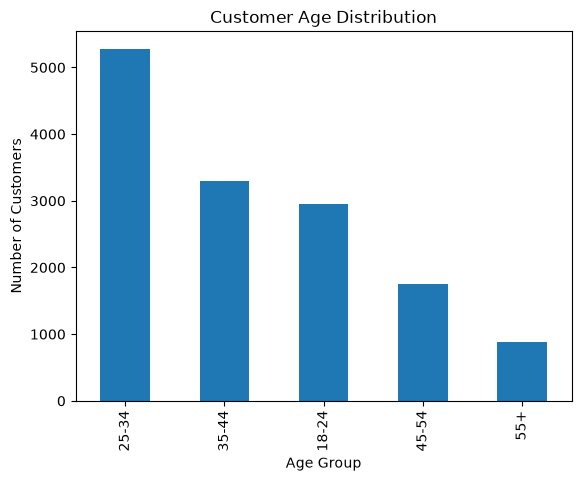

age_band
25-34    37.270545
35-44    23.263202
18-24    20.848630
45-54    12.411748
55+       6.205874
Name: proportion, dtype: float64


In [138]:
print(customers["age_band"].value_counts())

customers["age_band"].value_counts().plot(kind="bar")

plt.title("Customer Age Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()

print(customers["age_band"].value_counts(normalize=True) * 100)

# 2. Where are the customers located?

home_area
Kitsilano         3356
Point Grey        2592
Fairview          1981
Downtown          1981
Mount Pleasant    1637
Burnaby           1098
Other              696
Richmond           676
Name: count, dtype: int64


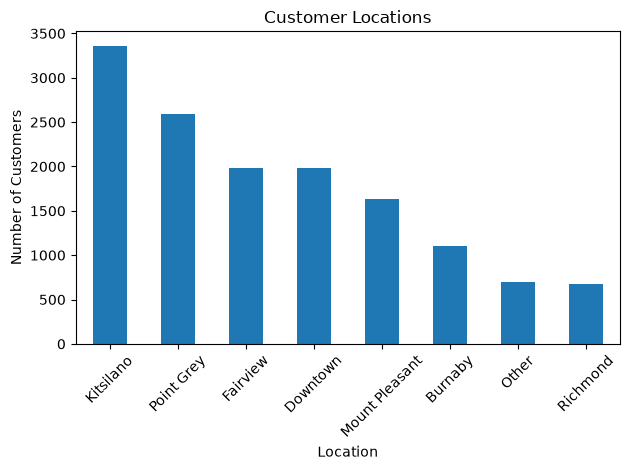

In [139]:
print(customers["home_area"].value_counts())

customers["home_area"].value_counts().plot(kind="bar")

plt.title("Customer Locations")
plt.xlabel("Location")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# How Do Customers Discover Lululime?

acquisition_channel
Walk-in             7625
Social Media        3532
Referral            2923
Pilates Campaign     360
Name: count, dtype: int64


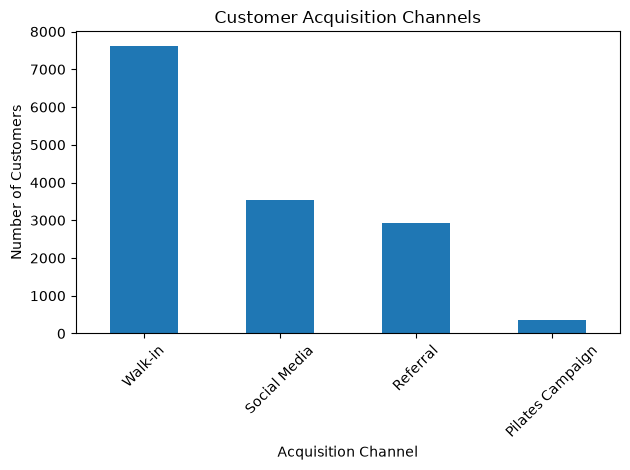

acquisition_channel
Walk-in             52.804709
Social Media        24.459834
Referral            20.242382
Pilates Campaign     2.493075
Name: proportion, dtype: float64


In [140]:
print(customers["acquisition_channel"].value_counts())

customers["acquisition_channel"].value_counts().plot(kind="bar")

plt.title("Customer Acquisition Channels")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(customers["acquisition_channel"].value_counts(normalize=True) * 100)

# Do different age groups discover Lululime through different channels?

acquisition_channel  Pilates Campaign  Referral  Social Media  Walk-in
age_band                                                              
18-24                              59       600           722     1572
25-34                             148      1059          1235     2837
35-44                              80       677           824     1714
45-54                              49       365           466      878
55+                                19       167           217      476


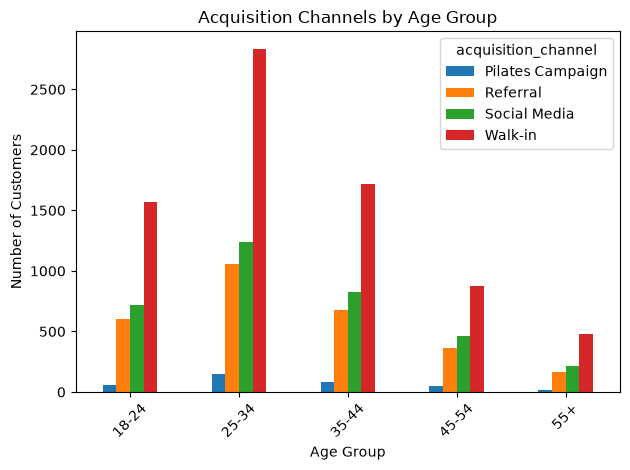

acquisition_channel  Pilates Campaign  Referral  Social Media  Walk-in
age_band                                                              
18-24                            2.00     20.32         24.45    53.23
25-34                            2.80     20.06         23.39    53.74
35-44                            2.43     20.55         25.01    52.02
45-54                            2.79     20.76         26.51    49.94
55+                              2.16     19.00         24.69    54.15


In [141]:
print(pd.crosstab(customers["age_band"], customers["acquisition_channel"]))
pd.crosstab(customers["age_band"], customers["acquisition_channel"]).plot(kind="bar")

plt.title("Acquisition Channels by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

table = pd.crosstab(customers["age_band"], customers["acquisition_channel"], normalize="index") * 100

print(table.round(2))

# Which product categories are most popular among different age groups?

category  Accessories  Hoodies & Sweaters  Leggings  Outerwear  Shorts  \
age_band                                                                 
18-24           13486                4110      6717       2530    4834   
25-34           27857               10523     17159       7750   11238   
35-44           19111                8596     14194       6934    8617   
45-54           10346                4783      8181       3888    4689   
55+              4621                2131      3503       1701    2090   

category  Sports Bras  Tank Tops   Tops  
age_band                                 
18-24            6030       4439   6653  
25-34           12946       9982  16049  
35-44            9642       7337  12065  
45-54            5263       4066   6650  
55+              2327       1686   3073  


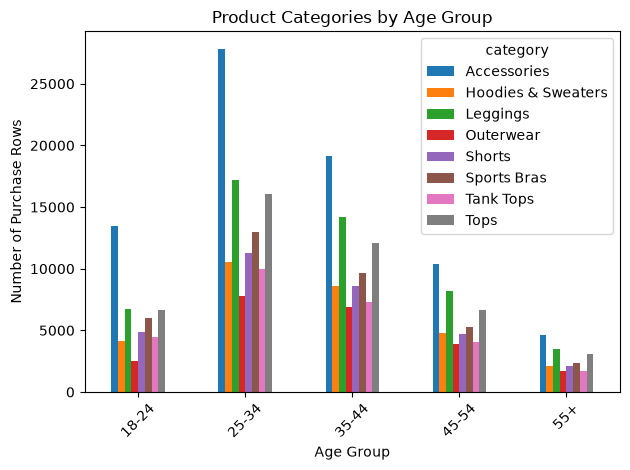

category  Accessories  Hoodies & Sweaters  Leggings  Outerwear  Shorts  \
age_band                                                                 
18-24           27.64                8.42     13.76       5.18    9.91   
25-34           24.54                9.27     15.12       6.83    9.90   
35-44           22.09                9.94     16.41       8.02    9.96   
45-54           21.61                9.99     17.09       8.12    9.80   
55+             21.87               10.08     16.58       8.05    9.89   

category  Sports Bras  Tank Tops   Tops  
age_band                                 
18-24           12.36       9.10  13.63  
25-34           11.41       8.79  14.14  
35-44           11.15       8.48  13.95  
45-54           11.00       8.49  13.89  
55+             11.01       7.98  14.54  


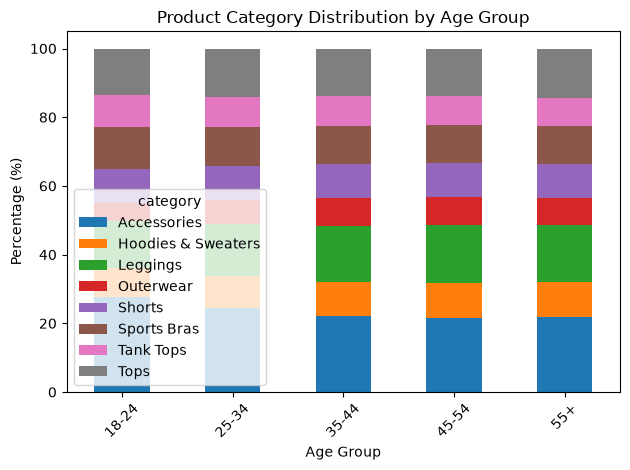

In [142]:
purchases = df[df["row_type"] == "Purchase"]

table = pd.crosstab(purchases["age_band"], purchases["category"])
print(table)

table.plot(kind="bar")

plt.title("Product Categories by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Purchase Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

table_percent = pd.crosstab(purchases["age_band"], purchases["category"], normalize="index") * 100

print(table_percent.round(2))

table_percent.plot(kind="bar", stacked=True)

plt.title("Product Category Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Do customers acquired through different channels purchase different product categories?

category             Accessories  Hoodies & Sweaters  Leggings  Outerwear  \
acquisition_channel                                                         
Pilates Campaign             713                 138       327        101   
Referral                   16129                6442     10626       4961   
Social Media               18737                7559     12716       5885   
Walk-in                    41275               16564     27045      12293   

category             Shorts  Sports Bras  Tank Tops   Tops  
acquisition_channel                                         
Pilates Campaign        260          326        213    331  
Referral               6797         7614       5891   9611  
Social Media           8043         9397       6981  11211  
Walk-in               16947        19503      14936  24131  


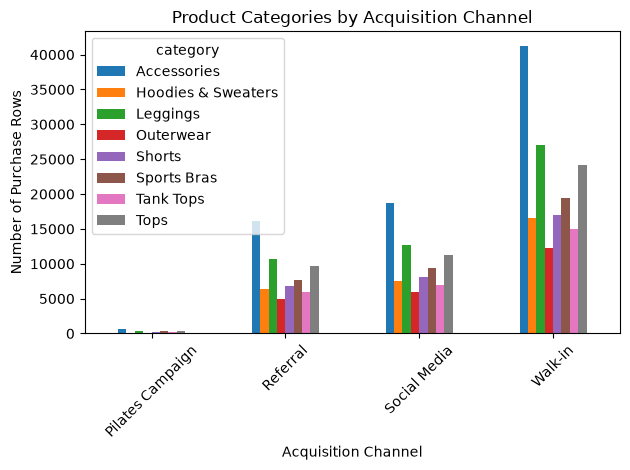

category             Accessories  Hoodies & Sweaters  Leggings  Outerwear  \
acquisition_channel                                                         
Pilates Campaign           29.60                5.73     13.57       4.19   
Referral                   23.69                9.46     15.61       7.29   
Social Media               23.27                9.39     15.79       7.31   
Walk-in                    23.90                9.59     15.66       7.12   

category             Shorts  Sports Bras  Tank Tops   Tops  
acquisition_channel                                         
Pilates Campaign      10.79        13.53       8.84  13.74  
Referral               9.99        11.19       8.65  14.12  
Social Media           9.99        11.67       8.67  13.92  
Walk-in                9.81        11.29       8.65  13.97  


In [143]:
table = pd.crosstab(purchases["acquisition_channel"], purchases["category"])

print(table)

table.plot(kind="bar")

plt.title("Product Categories by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Purchase Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

table_percent = pd.crosstab(purchases["acquisition_channel"], purchases["category"], normalize="index") * 100

print(table_percent.round(2))

# How many customers made their first purchase each month?

customer_id
100053   2023-08-17
100061   2023-02-08
100073   2025-02-18
100081   2022-11-17
100090   2025-12-11
Name: date, dtype: datetime64[ns]
date
2022-11    2341
2022-12    1446
2023-01     505
2023-02     372
2023-03     386
2023-04     399
2023-05     353
2023-06     319
2023-07     299
2023-08     297
2023-09     266
2023-10     233
2023-11     299
2023-12     340
2024-01     197
2024-02     148
2024-03     171
2024-04     175
2024-05     205
2024-06     197
2024-07     189
2024-08     188
2024-09     232
2024-10     183
2024-11     198
2024-12     272
2025-01     279
2025-02     233
2025-03     289
2025-04     153
2025-05     180
2025-06     154
2025-07     177
2025-08     206
2025-09     225
2025-10     187
2025-11     209
2025-12     280
2026-01     138
2026-02     128
2026-03     133
2026-04     175
2026-05     178
2026-06     168
2026-07     173
2026-08     184
2026-09     203
2026-10     170
Freq: M, Name: count, dtype: int64


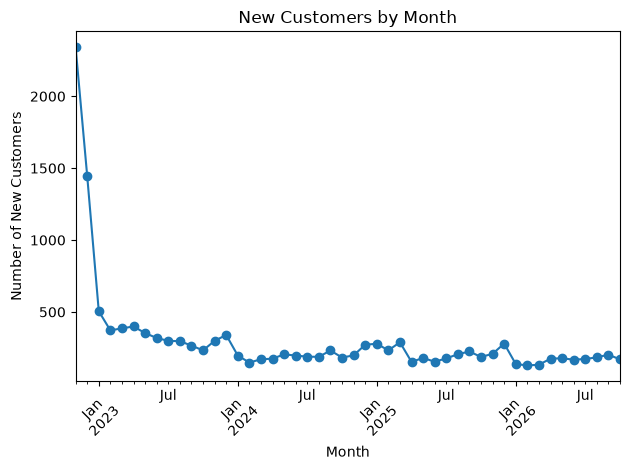

In [144]:
purchases = df[df["row_type"] == "Purchase"].copy()
purchases["date"] = pd.to_datetime(purchases["date"])
first_purchase = purchases.groupby("customer_id")["date"].min()

print(first_purchase.head())

new_customers = first_purchase.dt.to_period("M").value_counts().sort_index()

print(new_customers)

new_customers.plot(kind="line", marker="o")

plt.title("New Customers by Month")
plt.xlabel("Month")
plt.ylabel("Number of New Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# How many existing customers come back to purchase each month?

month
2022-11    2341
2022-12    2868
2023-01    2017
2023-02    1735
2023-03    2000
2023-04    2163
2023-05    2339
2023-06    2179
2023-07    2208
2023-08    2233
2023-09    2408
2023-10    2239
2023-11    2545
2023-12    3014
2024-01    2153
2024-02    1829
2024-03    1867
2024-04    1793
2024-05    1772
2024-06    1704
2024-07    1697
2024-08    1749
2024-09    1950
2024-10    1846
2024-11    2001
2024-12    2497
2025-01    1923
2025-02    1697
2025-03    1906
2025-04    1881
2025-05    2047
2025-06    1965
2025-07    1997
2025-08    2062
2025-09    2173
2025-10    2006
2025-11    2214
2025-12    2655
2026-01    1857
2026-02    1678
2026-03    1872
2026-04    2000
2026-05    2200
2026-06    2030
2026-07    2035
2026-08    2094
2026-09    2208
2026-10    2093
Freq: M, Name: customer_id, dtype: int64
month
2022-11       0
2022-12    1422
2023-01    1512
2023-02    1363
2023-03    1614
2023-04    1764
2023-05    1986
2023-06    1860
2023-07    1909
2023-08    1936
2023-09    2142
202

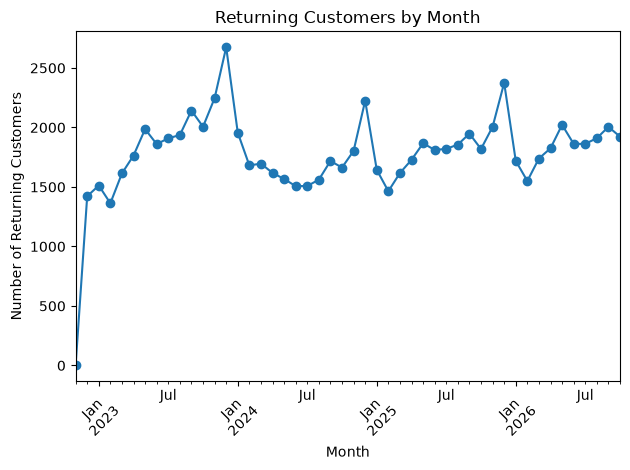

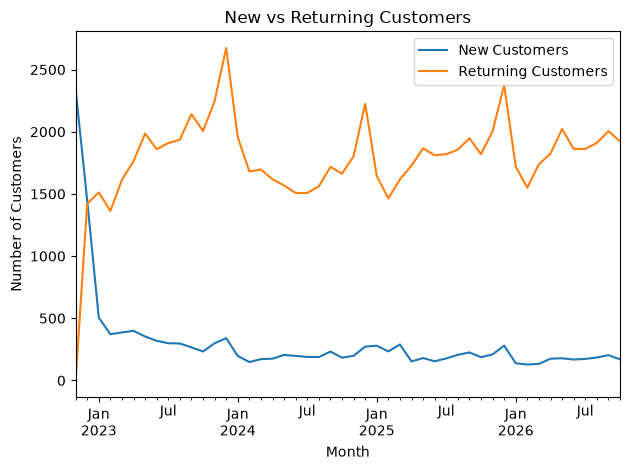

In [145]:
purchases["month"] = purchases["date"].dt.to_period("M")

active_customers = purchases.groupby("month")["customer_id"].nunique()

print(active_customers)

returning_customers = active_customers - new_customers.reindex(active_customers.index, fill_value=0)

print(returning_customers)

returning_customers.plot(kind="line", marker="o")

plt.title("Returning Customers by Month")
plt.xlabel("Month")
plt.ylabel("Number of Returning Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

new_customers.plot(label="New Customers")
returning_customers.plot(label="Returning Customers")

plt.title("New vs Returning Customers")
plt.xlabel("Month")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

# What percentage of Lululime customers have purchased more than once?

customer_id
100053     5
100061     6
100073     3
100081    17
100090     1
Name: transaction_id, dtype: int64
transaction_id
True     11702
False     2730
Name: count, dtype: int64
Repeat Customer Rate: 81.08 %


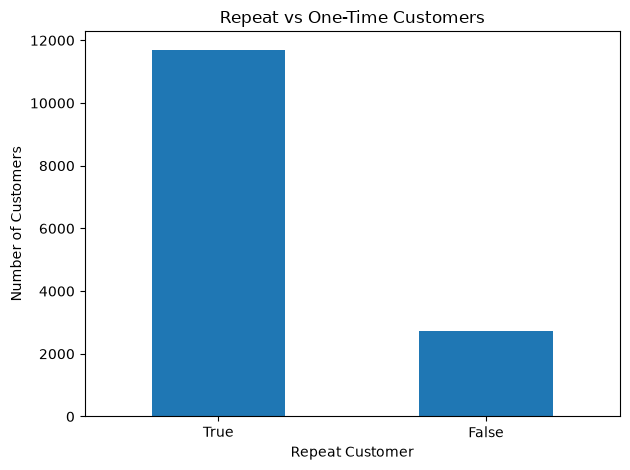

In [146]:
frequency = purchases.groupby("customer_id")["transaction_id"].nunique()

print(frequency.head())

repeat = frequency >= 2

print(repeat.value_counts())

repeat_rate = repeat.mean() * 100

print("Repeat Customer Rate:", round(repeat_rate, 2), "%")

repeat.value_counts().plot(kind="bar")

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Repeat Customer")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# How many times does each customer purchase from Lululime?

count    14432.000000
mean        11.674266
std         20.685427
min          1.000000
25%          2.000000
50%          4.000000
75%         11.000000
max        150.000000
Name: transaction_id, dtype: float64


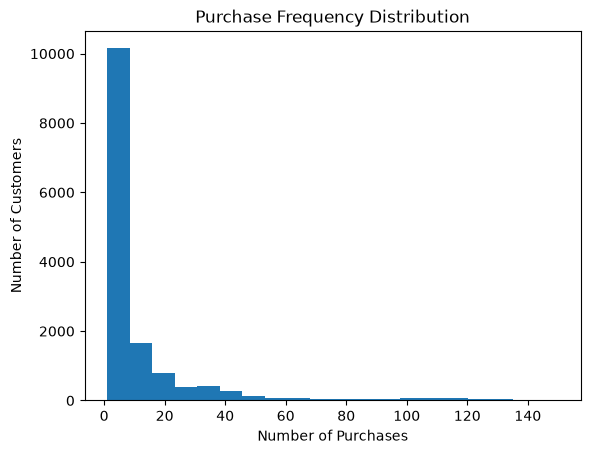

Average Purchases: 11.674265521064301
Median Purchases: 4.0
customer_id
100053   2025-01-18
100061   2023-11-20
100073   2025-09-30
100081   2024-07-20
100090   2025-12-11
Name: date, dtype: datetime64[ns]
count    14432.000000
mean       577.518501
std        467.976834
min          0.000000
25%         91.000000
50%        542.000000
75%        997.000000
max       1460.000000
Name: date, dtype: float64


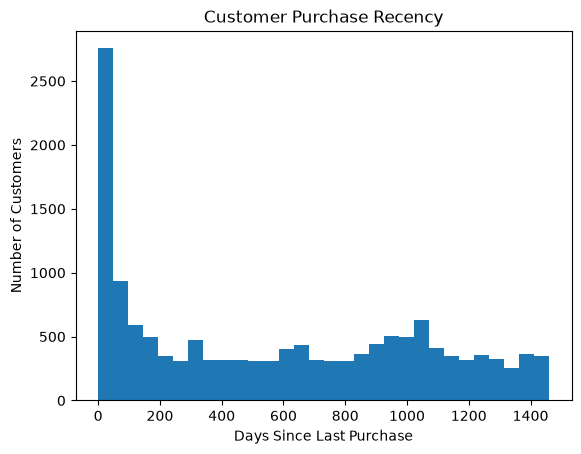

             frequency  recency
customer_id                    
100053               5      651
100061               6     1076
100073               3      396
100081              17      833
100090               1      324


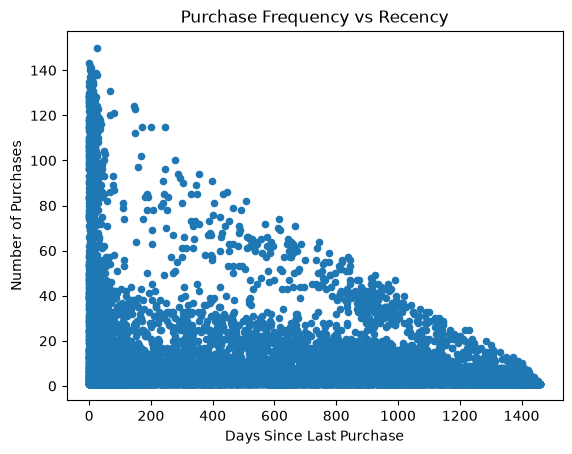

In [147]:
frequency = purchases.groupby("customer_id")["transaction_id"].nunique()

print(frequency.describe())

frequency.plot(kind="hist", bins=20)

plt.title("Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.show()

print("Average Purchases:", frequency.mean())
print("Median Purchases:", frequency.median())

last_purchase = purchases.groupby("customer_id")["date"].max()

print(last_purchase.head())

reference_date = purchases["date"].max()

recency = (reference_date - last_purchase).dt.days

print(recency.describe())

recency.plot(kind="hist", bins=30)

plt.title("Customer Purchase Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.show()

customer_behavior = pd.DataFrame({"frequency": frequency,"recency": recency})

print(customer_behavior.head())

customer_behavior.plot(kind="scatter", x="recency", y="frequency")

plt.title("Purchase Frequency vs Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Purchases")
plt.show()

# Cohort

In [148]:
purchases["cohort"] = (purchases.groupby("customer_id")["date"].transform("min").dt.to_period("M"))

print(purchases[["customer_id", "cohort"]].head())

   customer_id   cohort
0       180984  2022-11
1       180984  2022-11
2       939082  2022-11
3       884202  2022-11
4       884202  2022-11


In [149]:
purchases["purchase_month"] = purchases["date"].dt.to_period("M")

print(purchases[["customer_id", "cohort", "purchase_month"]].head())

   customer_id   cohort purchase_month
0       180984  2022-11        2022-11
1       180984  2022-11        2022-11
2       939082  2022-11        2022-11
3       884202  2022-11        2022-11
4       884202  2022-11        2022-11


In [150]:
purchases["cohort_month"] = ((purchases["purchase_month"].dt.year - purchases["cohort"].dt.year) * 12+ purchases["purchase_month"].dt.month- purchases["cohort"].dt.month)

print(purchases[["customer_id", "cohort", "cohort_month"]].head())

   customer_id   cohort  cohort_month
0       180984  2022-11             0
1       180984  2022-11             0
2       939082  2022-11             0
3       884202  2022-11             0
4       884202  2022-11             0


In [151]:
cohort_counts = purchases.groupby(["cohort", "cohort_month"])["customer_id"].nunique().unstack()

cohort_sizes = cohort_counts[0]

retention = cohort_counts.div(cohort_sizes, axis=0) * 100

print(retention.round(1))

cohort_month     0     1     2     3     4     5     6     7     8     9   \
cohort                                                                      
2022-11       100.0  60.7  44.8  38.5  43.2  44.2  46.3  41.8  40.8  41.1   
2022-12       100.0  32.0  25.2  28.1  28.6  30.6  28.4  27.2  27.0  27.2   
2023-01       100.0  19.4  21.2  24.6  26.9  22.8  25.5  21.6  26.1  22.2   
2023-02       100.0  23.9  26.1  25.0  23.9  26.6  20.2  21.8  19.6  25.5   
2023-03       100.0  24.4  27.2  22.5  20.2  20.5  22.5  21.0  24.9  27.2   
2023-04       100.0  31.3  25.8  23.1  24.6  26.8  21.6  21.3  25.8  19.8   
2023-05       100.0  21.8  22.7  20.7  22.7  25.5  25.2  28.6  15.9  15.3   
2023-06       100.0  26.3  25.4  27.9  25.7  25.4  30.7  18.2  16.6  13.8   
2023-07       100.0  22.7  23.7  26.8  24.4  31.1  21.1  15.4  15.4  11.7   
2023-08       100.0  26.9  26.9  32.0  36.4  21.5  16.5  17.2  15.2  16.2   
2023-09       100.0  34.2  32.0  33.8  27.8  20.7  18.8  18.4  18.4  16.2   

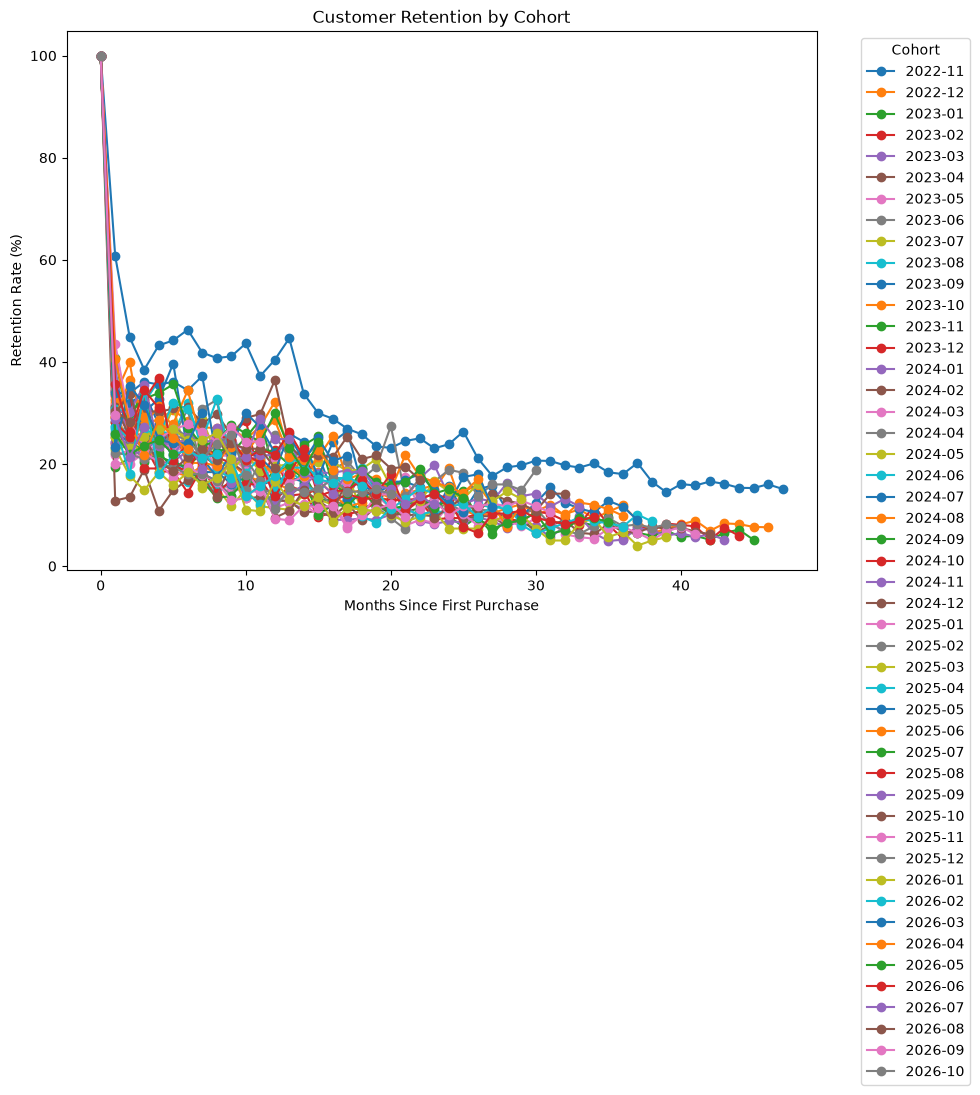

In [153]:
retention.T.plot(figsize=(12, 7), marker="o")

plt.title("Customer Retention by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Retention Rate (%)")
plt.legend(title="Cohort", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.subplots_adjust(right=0.75)
plt.show()

# Do loyalty members actually purchase more frequently than non-members?

In [154]:
customers["loyalty_member"] = customers["loyalty_join_date"].notna()

print(customers["loyalty_member"].value_counts())

loyalty_member
False    7722
True     6718
Name: count, dtype: int64


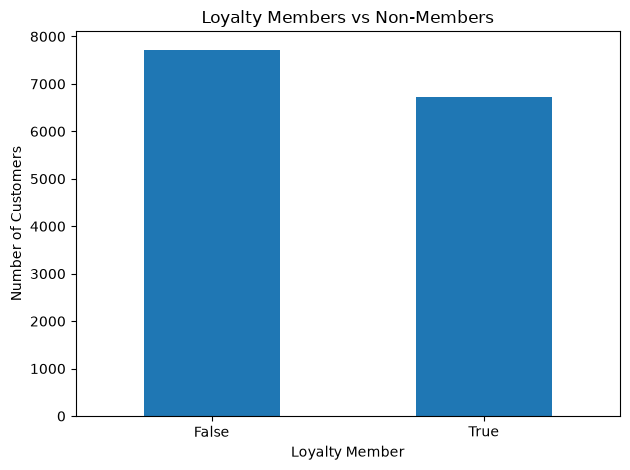

In [155]:
customers["loyalty_member"].value_counts().plot(kind="bar")

plt.title("Loyalty Members vs Non-Members")
plt.xlabel("Loyalty Member")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [156]:
loyalty_analysis = customers[["customer_id", "loyalty_member"]].merge(frequency.rename("frequency"), on="customer_id", how="left")

loyalty_analysis["frequency"] = loyalty_analysis["frequency"].fillna(0)

print(loyalty_analysis.head())

   customer_id  loyalty_member  frequency
0       100053           False        5.0
1       100061           False        6.0
2       100073            True        3.0
3       100081            True       17.0
4       100090           False        1.0


In [157]:
average_frequency = loyalty_analysis.groupby("loyalty_member")["frequency"].mean()

print(average_frequency)

loyalty_member
False     4.487050
True     19.921703
Name: frequency, dtype: float64


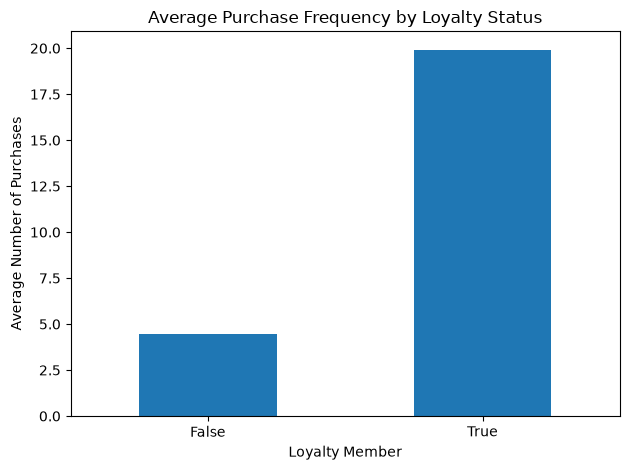

In [158]:
average_frequency.plot(kind="bar")

plt.title("Average Purchase Frequency by Loyalty Status")
plt.xlabel("Loyalty Member")
plt.ylabel("Average Number of Purchases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [159]:
loyalty_analysis["repeat_customer"] = (loyalty_analysis["frequency"] >= 2)

repeat_by_loyalty = loyalty_analysis.groupby("loyalty_member")["repeat_customer"].mean() * 100

print(repeat_by_loyalty.round(2))

loyalty_member
False    71.45
True     92.07
Name: repeat_customer, dtype: float64


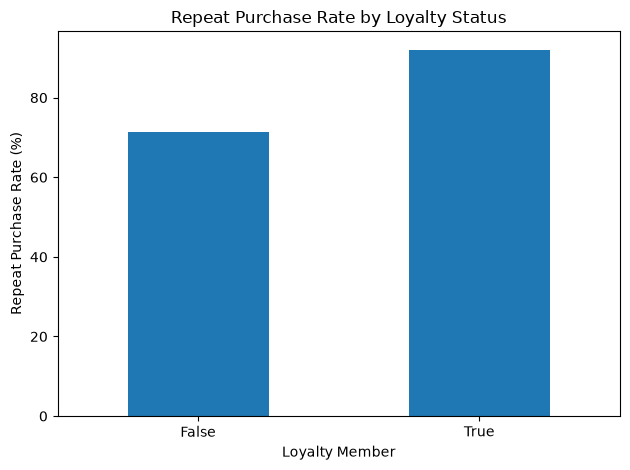

In [160]:
repeat_by_loyalty.plot(kind="bar")

plt.title("Repeat Purchase Rate by Loyalty Status")
plt.xlabel("Loyalty Member")
plt.ylabel("Repeat Purchase Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# What percentage of customers have used Lululime's repair program?

In [161]:
print(sales["row_type"].value_counts())

row_type
Purchase           323703
Return              17576
Repair Drop-off      5497
Repair Pickup        5238
Name: count, dtype: int64


In [162]:
repairs = sales[sales["row_type"].isin(["Repair Drop-off", "Repair Pickup"])].copy()

print(repairs.head())

       transaction_id        date      time  customer_id item_id  quantity  \
196383       T1106705  2025-04-01  10:44:41       124126     R02         1   
196402       T1106714  2025-04-01  11:40:46       504038     R01         1   
196421       T1106726  2025-04-01  12:19:02       269978     R01         1   
196424       T1106728  2025-04-01  12:24:31       145071     R01         1   
196474       T1106755  2025-04-01  15:15:49       275463     R01         1   

        unit_price_paid         row_type original_transaction_id  \
196383              0.0  Repair Drop-off                     NaN   
196402              0.0  Repair Drop-off                     NaN   
196421              0.0  Repair Drop-off                     NaN   
196424              0.0  Repair Drop-off                     NaN   
196474              0.0  Repair Drop-off                     NaN   

       tier_at_purchase  points_earned  points_redeemed  points_balance_after  \
196383           Member            0.0   

In [163]:
repair_customers = repairs["customer_id"].nunique()

total_customers = customers["customer_id"].nunique()

repair_rate = repair_customers / total_customers * 100

print("Repair Customers:", repair_customers)
print("Repair Participation Rate:", round(repair_rate, 2), "%")

Repair Customers: 2175
Repair Participation Rate: 15.06 %


In [164]:
repair_ids = repairs["customer_id"].unique()

customers["repair_user"] = customers["customer_id"].isin(repair_ids)

print(customers["repair_user"].value_counts())

repair_user
False    12265
True      2175
Name: count, dtype: int64


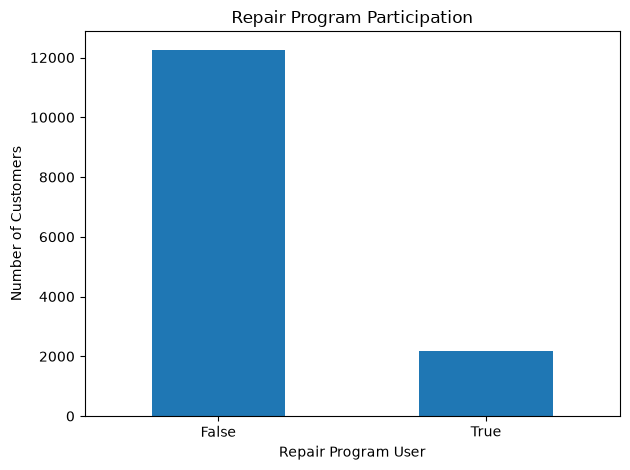

In [165]:
customers["repair_user"].value_counts().plot(kind="bar")

plt.title("Repair Program Participation")
plt.xlabel("Repair Program User")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [166]:
repair_analysis = customers[["customer_id", "repair_user"]].merge(frequency.rename("frequency"), on="customer_id", how="left")

repair_analysis["frequency"] = repair_analysis["frequency"].fillna(0)

average_frequency = repair_analysis.groupby("repair_user")["frequency"].mean()

print(average_frequency)

repair_user
False     6.598859
True     40.251954
Name: frequency, dtype: float64


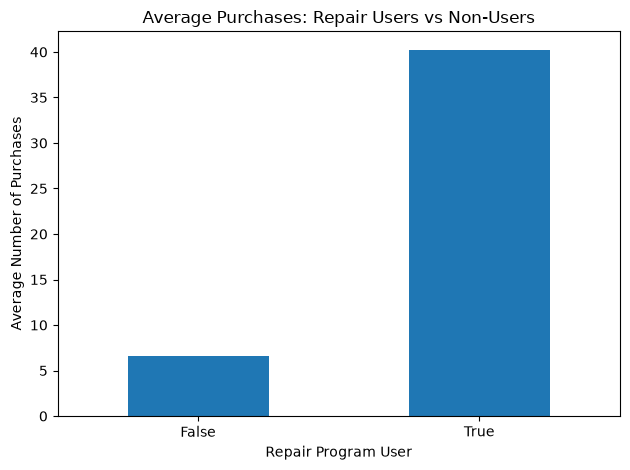

In [167]:
average_frequency.plot(kind="bar")

plt.title("Average Purchases: Repair Users vs Non-Users")
plt.xlabel("Repair Program User")
plt.ylabel("Average Number of Purchases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Are customers who use the repair program more likely to make repeat purchases?

In [168]:
repair_analysis["repeat_customer"] = (repair_analysis["frequency"] >= 2)

print(repair_analysis.head())

   customer_id  repair_user  frequency  repeat_customer
0       100053        False        5.0             True
1       100061        False        6.0             True
2       100073        False        3.0             True
3       100081        False       17.0             True
4       100090        False        1.0            False


In [169]:
repair_repeat_rate = repair_analysis.groupby("repair_user")["repeat_customer"].mean() * 100

print(repair_repeat_rate.round(2))

repair_user
False    77.68
True     99.95
Name: repeat_customer, dtype: float64


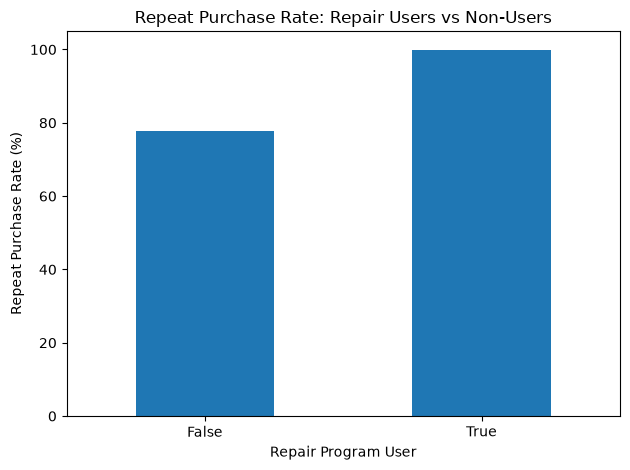

In [170]:
repair_repeat_rate.plot(kind="bar")

plt.title("Repeat Purchase Rate: Repair Users vs Non-Users")
plt.xlabel("Repair Program User")
plt.ylabel("Repeat Purchase Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [171]:
repair_recency = repair_analysis.merge(recency.rename("recency"),on="customer_id",how="left")

print(repair_recency.head())

   customer_id  repair_user  frequency  repeat_customer  recency
0       100053        False        5.0             True    651.0
1       100061        False        6.0             True   1076.0
2       100073        False        3.0             True    396.0
3       100081        False       17.0             True    833.0
4       100090        False        1.0            False    324.0


In [172]:
average_recency = repair_recency.groupby("repair_user")["recency"].mean()

print(average_recency)

repair_user
False    666.932039
True      73.637241
Name: recency, dtype: float64


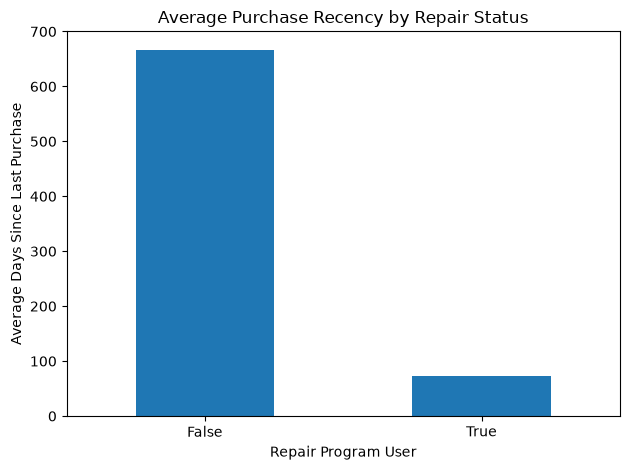

In [173]:
average_recency.plot(kind="bar")

plt.title("Average Purchase Recency by Repair Status")
plt.xlabel("Repair Program User")
plt.ylabel("Average Days Since Last Purchase")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [174]:
difference = (repair_repeat_rate[True] - repair_repeat_rate[False])

print("Difference:", round(difference, 2), "percentage points")

Difference: 22.27 percentage points


In [175]:
purchases["revenue"] = (purchases["quantity"] * purchases["unit_price_paid"])

monetary = purchases.groupby("customer_id")["revenue"].sum()

print(monetary.head())

customer_id
100053     645.2
100061    1100.0
100073     218.0
100081    3086.0
100090     844.0
Name: revenue, dtype: float64


Suppose Customer A bought:
2 leggings at $50 each = $100
1 jacket at $120 = $120

Their total monetary value (how much money has a customer spent at a business) is:
M = 100 + 120 = $220

This is gross purchase spending, before accounting for returns or refunds.

In [176]:
rfm = pd.DataFrame({"recency": recency, "frequency": frequency, "monetary": monetary})

print(rfm.head())

             recency  frequency  monetary
customer_id                              
100053           651          5     645.2
100061          1076          6    1100.0
100073           396          3     218.0
100081           833         17    3086.0
100090           324          1     844.0


In [177]:
print(rfm.describe())

            recency     frequency      monetary
count  14432.000000  14432.000000  14432.000000
mean     577.518501     11.674266   1919.805183
std      467.976834     20.685427   3643.040731
min        0.000000      1.000000     15.400000
25%       91.000000      2.000000    270.000000
50%      542.000000      4.000000    672.000000
75%      997.000000     11.000000   1746.150000
max     1460.000000    150.000000  37422.400000


In [178]:
rfm["R_score"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)

rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["M_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

print(rfm.head())

             recency  frequency  monetary  R_score  F_score  M_score
customer_id                                                         
100053           651          5     645.2        3        3        3
100061          1076          6    1100.0        1        3        4
100073           396          3     218.0        3        2        2
100081           833         17    3086.0        2        5        5
100090           324          1     844.0        4        1        3


In [179]:
def segment_customer(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4 and row["M_score"] >= 4:
        return "Champions"
    elif row["R_score"] <= 2 and row["F_score"] >= 4 and row["M_score"] >= 4:
        return "High-Value At Risk"
    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Loyal Customers"
    elif row["R_score"] >= 4:
        return "Recent Customers"
    elif row["R_score"] <= 2:
        return "Inactive Customers"
    else:
        return "Occasional Customers"


rfm["segment"] = rfm.apply(segment_customer, axis=1)

print(rfm["segment"].value_counts())

segment
Inactive Customers      4511
Champions               2957
Loyal Customers         2870
Recent Customers        1611
High-Value At Risk      1262
Occasional Customers    1221
Name: count, dtype: int64


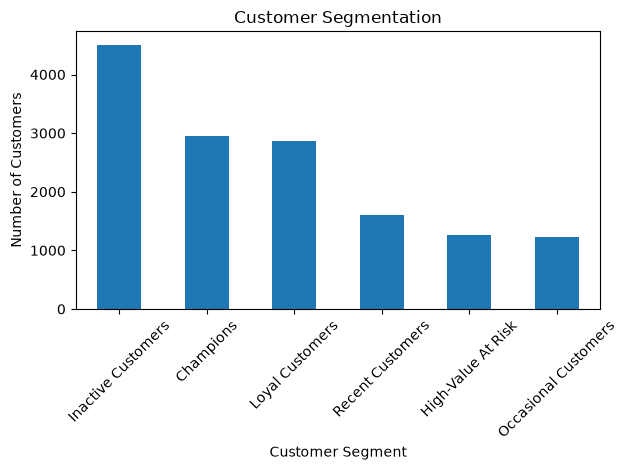

In [180]:
rfm["segment"].value_counts().plot(kind="bar")

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [181]:
segment_revenue = rfm.groupby("segment")["monetary"].sum()

print(segment_revenue.sort_values(ascending=False))

segment
Champions               17076125.8
Loyal Customers          4569775.6
High-Value At Risk       3386399.8
Inactive Customers       1930496.9
Recent Customers          437580.1
Occasional Customers      306250.2
Name: monetary, dtype: float64


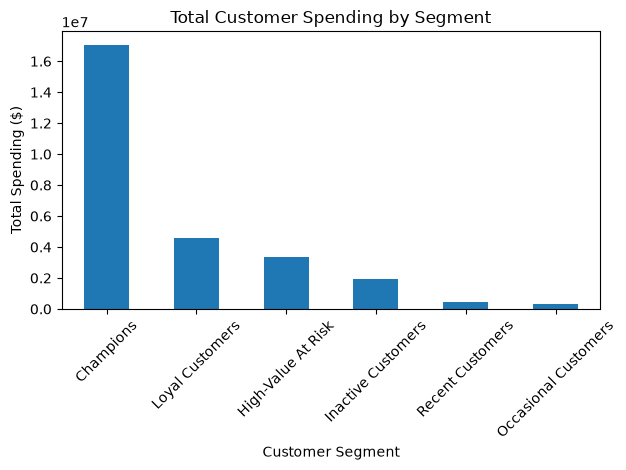

In [182]:
segment_revenue.sort_values(ascending=False).plot(kind="bar")

plt.title("Total Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Spending ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [183]:
revenue_share = (segment_revenue / segment_revenue.sum() * 100)

print(revenue_share.sort_values(ascending=False).round(2))

segment
Champions               61.63
Loyal Customers         16.49
High-Value At Risk      12.22
Inactive Customers       6.97
Recent Customers         1.58
Occasional Customers     1.11
Name: monetary, dtype: float64


In [184]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

import numpy as np
from sklearn.preprocessing import StandardScaler

# Select RFM variables
X = rfm[["recency", "frequency", "monetary"]].copy()

# Reduce the effect of extreme values
X_log = np.log1p(X)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print(X_scaled[:5])

[[ 0.53104403 -0.08176163 -0.0684255 ]
 [ 0.82200274  0.06824372  0.31352975]
 [ 0.24343719 -0.47632319 -0.8440249 ]
 [ 0.67376608  0.98730738  1.05253212]
 [ 0.1274276  -1.15083063  0.12383879]]


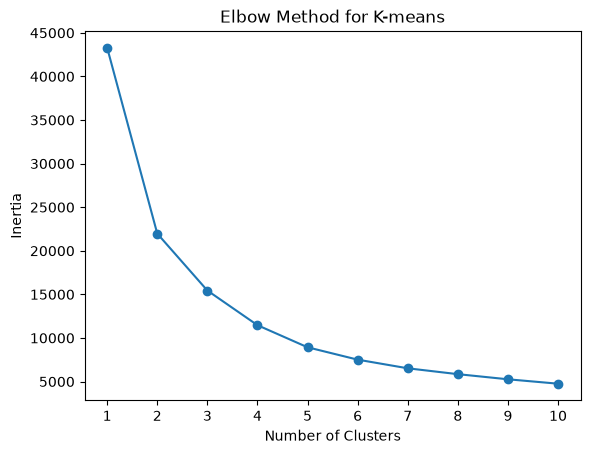

In [185]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")

plt.title("Elbow Method for K-means")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.show()

In [186]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["cluster"].value_counts())

cluster
3    5900
1    4468
0    2232
2    1832
Name: count, dtype: int64


In [187]:
cluster_summary = rfm.groupby("cluster")[["recency", "frequency", "monetary"]].median()

print(cluster_summary.round(2))

         recency  frequency  monetary
cluster                              
0           42.0        4.0    623.80
1          736.0        8.0   1381.00
2           15.0       39.0   6550.35
3          904.0        2.0    244.00


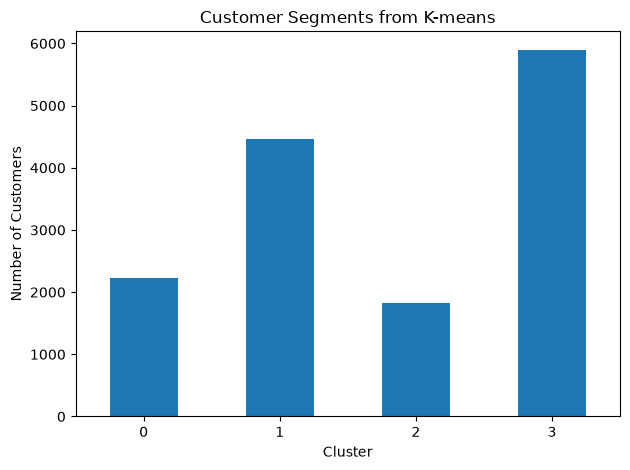

In [188]:
rfm["cluster"].value_counts().sort_index().plot(kind="bar")

plt.title("Customer Segments from K-means")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [189]:
cluster_summary = rfm.groupby("cluster")[["recency", "frequency", "monetary"]].median()

print(cluster_summary.round(2))

         recency  frequency  monetary
cluster                              
0           42.0        4.0    623.80
1          736.0        8.0   1381.00
2           15.0       39.0   6550.35
3          904.0        2.0    244.00


In [190]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, kmeans.labels_, sample_size=5000, random_state=42)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.391


In [191]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    scores.append(score)
    print("Clusters:", k, "Silhouette Score:", round(score, 3))

Clusters: 2 Silhouette Score: 0.445
Clusters: 3 Silhouette Score: 0.354
Clusters: 4 Silhouette Score: 0.391
Clusters: 5 Silhouette Score: 0.376
Clusters: 6 Silhouette Score: 0.385
Clusters: 7 Silhouette Score: 0.343
Clusters: 8 Silhouette Score: 0.341


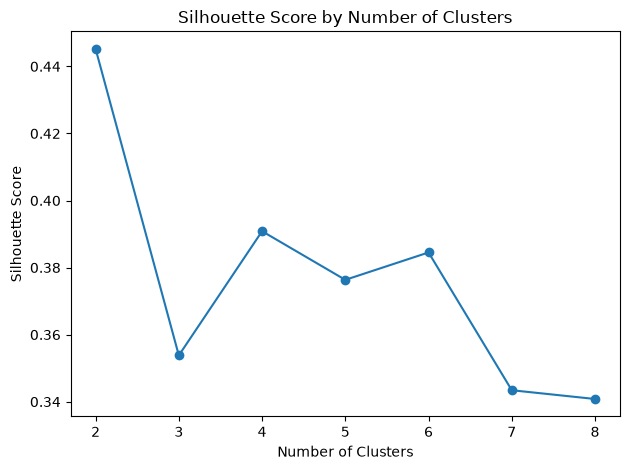

In [192]:
plt.plot(range(2, 9), scores, marker="o")

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.tight_layout()
plt.show()

In [193]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)

rfm["cluster_2"] = kmeans_2.fit_predict(X_scaled)

print(rfm.groupby("cluster_2")[["recency", "frequency", "monetary"]].median())

           recency  frequency  monetary
cluster_2                              
0             65.0       18.0    2918.9
1            761.0        3.0     386.0


In [194]:
rfm.to_csv("customer_segments.csv")

print("Customer segments saved!")

Customer segments saved!


Predicting Future Repeat Purchases

In [195]:
purchases["date"] = pd.to_datetime(purchases["date"])

print("First purchase:", purchases["date"].min())
print("Last purchase:", purchases["date"].max())

First purchase: 2022-11-01 00:00:00
Last purchase: 2026-10-31 00:00:00


In [198]:
# Ensure dates use pandas datetime format
purchases["date"] = pd.to_datetime(purchases["date"], errors="coerce")

# Define cutoff date
cutoff = pd.Timestamp("2026-08-01")
from datetime import datetime, timedelta

cutoff = datetime(2026, 8, 1)
end_date = cutoff + timedelta(days=90)

# Split past and future purchases
past = purchases.loc[purchases["date"] < cutoff].copy()

future = purchases.loc[(purchases["date"] >= cutoff) & (purchases["date"] < end_date)].copy()

print("Past purchase rows:", len(past))
print("Future purchase rows:", len(future))

Past purchase rows: 301004
Future purchase rows: 22222


In [199]:
future_customers = future["customer_id"].unique()

print("Customers who purchased in next 90 days:", len(future_customers))

Customers who purchased in next 90 days: 3576


In [200]:
customer_ids = past["customer_id"].unique()

prediction_data = pd.DataFrame({"customer_id": customer_ids})

prediction_data["repeat_purchase_90d"] = (prediction_data["customer_id"].isin(future_customers).astype(int))

print(prediction_data.head())

   customer_id  repeat_purchase_90d
0       180984                    1
1       939082                    0
2       884202                    0
3       110076                    0
4       554756                    1


In [201]:
print(prediction_data["repeat_purchase_90d"].value_counts())

print(prediction_data["repeat_purchase_90d"].value_counts(normalize=True) * 100)

repeat_purchase_90d
0    10842
1     3033
Name: count, dtype: int64
repeat_purchase_90d
0    78.140541
1    21.859459
Name: proportion, dtype: float64


In [202]:
past = past.copy()

past["revenue"] = (past["quantity"] * past["unit_price_paid"])

historical_rfm = past.groupby("customer_id").agg(last_purchase=("date", "max"), frequency=("transaction_id", "nunique"), monetary=("revenue", "sum"))

historical_rfm["recency"] = (cutoff - historical_rfm["last_purchase"]).dt.days

print(historical_rfm.head())

            last_purchase  frequency  monetary  recency
customer_id                                            
100053         2025-01-18          5     645.2      560
100061         2023-11-20          6    1100.0      985
100073         2025-09-30          3     218.0      305
100081         2024-07-20         17    3086.0      742
100090         2025-12-11          1     844.0      233


In [203]:
prediction_data = prediction_data.merge(historical_rfm[["recency", "frequency", "monetary"]], on="customer_id", how="left")

print(prediction_data.head())

   customer_id  repeat_purchase_90d  recency  frequency  monetary
0       180984                    1       17        113   25850.9
1       939082                    0     1028         30    4964.0
2       884202                    0       98         13    2681.0
3       110076                    0      843         38    5998.9
4       554756                    1       20         46    9019.3


In [210]:

from datetime import datetime, timedelta

def make_prediction_data(cutoff):
    cutoff = datetime.fromisoformat(str(cutoff)[:10])
    end_date = cutoff + timedelta(days=90)

    past = purchases[purchases["date"] < cutoff].copy()

    future = purchases[(purchases["date"] >= cutoff) & (purchases["date"] < end_date)].copy()

    past["revenue"] = (past["quantity"] * past["unit_price_paid"])

    features = past.groupby("customer_id").agg(last_purchase=("date", "max"), frequency=("transaction_id", "nunique"), monetary=("revenue", "sum"))

    features["recency"] = (pd.Timestamp(cutoff) - features["last_purchase"]).dt.days

    features["repeat_purchase_90d"] = (features.index.isin(future["customer_id"]).astype(int))

    return features[["recency", "frequency", "monetary", "repeat_purchase_90d"]].reset_index()


In [211]:
test_data = make_prediction_data("2025-01-01")

print(test_data.head())
print(test_data.shape)

   customer_id  recency  frequency  monetary  repeat_purchase_90d
0       100053       82          4     607.2                    1
1       100061      408          6    1100.0                    0
2       100081      165         17    3086.0                    0
3       100126       12          3     588.0                    0
4       100154       76         18    2198.5                    0
(10210, 5)


In [214]:
training_dates = [
    "2024-01-01",
    "2024-04-01",
    "2024-07-01",
    "2024-10-01",
    "2025-01-01",
    "2025-04-01",
    "2025-07-01",
    "2025-10-01",
    "2026-01-01",
    "2026-04-01"]

training_data = pd.concat([make_prediction_data(date) for date in training_dates], ignore_index=True)

print(training_data.shape)

(105519, 5)


In [215]:
testing_data = make_prediction_data("2026-08-01")

print(testing_data.shape)

(13875, 5)


In [216]:
features = ["recency", "frequency", "monetary"]

X_train = training_data[features]
y_train = training_data["repeat_purchase_90d"]

X_test = testing_data[features]
y_test = testing_data["repeat_purchase_90d"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 105519
Testing rows: 13875


In [217]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

log_model.fit(X_train, y_train)

print("Logistic Regression trained!")

Logistic Regression trained!


In [218]:
log_predictions = log_model.predict(X_test)

print(log_predictions[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [219]:
from sklearn.metrics import classification_report

print(classification_report(y_test, log_predictions))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93     10842
           1       0.75      0.71      0.73      3033

    accuracy                           0.89     13875
   macro avg       0.83      0.82      0.83     13875
weighted avg       0.88      0.89      0.88     13875



In [220]:
from sklearn.ensemble import HistGradientBoostingClassifier

boost_model = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=8,
    learning_rate=0.05,
    random_state=42
)

boost_model.fit(X_train, y_train)

print("Gradient Boosting trained!")

Gradient Boosting trained!


In [221]:
boost_predictions = boost_model.predict(X_test)

print(boost_predictions[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [222]:
from sklearn.metrics import classification_report

print(classification_report(y_test, boost_predictions))

              precision    recall  f1-score   support

           0       0.90      0.96      0.93     10842
           1       0.81      0.63      0.71      3033

    accuracy                           0.89     13875
   macro avg       0.86      0.80      0.82     13875
weighted avg       0.88      0.89      0.88     13875



In [223]:
from sklearn.metrics import average_precision_score

log_prob = log_model.predict_proba(X_test)[:, 1]
boost_prob = boost_model.predict_proba(X_test)[:, 1]

print("Logistic Regression AP:", round(average_precision_score(y_test, log_prob), 3))

print("Gradient Boosting AP:", round(average_precision_score(y_test, boost_prob), 3))

Logistic Regression AP: 0.825
Gradient Boosting AP: 0.846


In [224]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(boost_model, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=42)

importance_df = pd.DataFrame({"feature": X_test.columns, "importance": importance.importances_mean})

print(importance_df.sort_values("importance", ascending=False))

     feature  importance
0    recency    0.576054
1  frequency    0.038443
2   monetary    0.017743


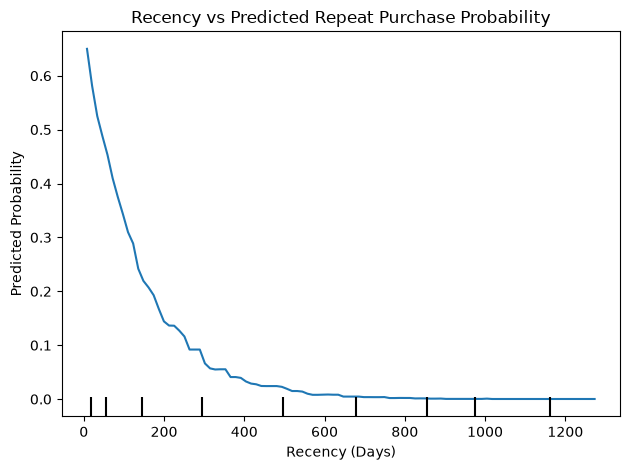

In [225]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

X_plot = X_test.astype(float)

PartialDependenceDisplay.from_estimator(boost_model, X_plot, features=["recency"], method="brute", response_method="predict_proba")

plt.title("Recency vs Predicted Repeat Purchase Probability")
plt.xlabel("Recency (Days)")
plt.ylabel("Predicted Probability")
plt.tight_layout()
plt.show()

In [226]:
segment_names = {0: "Recently Active", 1: "Previously Loyal, Now Inactive", 2: "VIP Customers", 3: "Long-Inactive, Low-Spending"}

rfm["customer_segment"] = rfm["cluster"].map(segment_names)

print(rfm["customer_segment"].value_counts())

customer_segment
Long-Inactive, Low-Spending       5900
Previously Loyal, Now Inactive    4468
Recently Active                   2232
VIP Customers                     1832
Name: count, dtype: int64


In [227]:
recommendations = {"Long-Inactive, Low-Spending": "Low-cost re-engagement", "Previously Loyal, Now Inactive": "Personalized win-back campaign", "Recently Active": "Product recommendations", "VIP Customers": "Exclusive loyalty benefits"}

rfm["recommended_action"] = (rfm["customer_segment"].map(recommendations))

print(rfm[["recency", "frequency", "monetary", "customer_segment", "recommended_action"]].head(10))

             recency  frequency  monetary                customer_segment  \
customer_id                                                                 
100053           651          5     645.2  Previously Loyal, Now Inactive   
100061          1076          6    1100.0  Previously Loyal, Now Inactive   
100073           396          3     218.0     Long-Inactive, Low-Spending   
100081           833         17    3086.0  Previously Loyal, Now Inactive   
100090           324          1     844.0     Long-Inactive, Low-Spending   
100126           431          6    1024.0  Previously Loyal, Now Inactive   
100154           744         18    2198.5  Previously Loyal, Now Inactive   
100206          1340          1     178.0     Long-Inactive, Low-Spending   
100249           289          2     990.0     Long-Inactive, Low-Spending   
100279          1321          1      98.0     Long-Inactive, Low-Spending   

                         recommended_action  
customer_id                  

In [228]:
rfm.to_csv("customer_segmentation_recommendations.csv")

In [229]:
testing_data["purchase_probability"] = (boost_model.predict_proba(X_test)[:, 1])

print(testing_data[["customer_id", "purchase_probability"]].head())

   customer_id  purchase_probability
0       100053              0.012296
1       100061              0.000479
2       100073              0.074285
3       100081              0.000753
4       100090              0.196627


In [230]:
segment_predictions = testing_data[["customer_id", "purchase_probability"]].merge(rfm[["customer_segment"]].reset_index(), on="customer_id", how="left")

print(segment_predictions.head())

   customer_id  purchase_probability                customer_segment
0       100053              0.012296  Previously Loyal, Now Inactive
1       100061              0.000479  Previously Loyal, Now Inactive
2       100073              0.074285     Long-Inactive, Low-Spending
3       100081              0.000753  Previously Loyal, Now Inactive
4       100090              0.196627     Long-Inactive, Low-Spending


In [231]:
segment_names = {0: "Recently Active", 1: "Previously Loyal, Now Inactive", 2: "VIP Customers", 3: "Long-Inactive, Low-Spending"}

rfm["customer_segment"] = rfm["cluster"].map(segment_names)

print(rfm["customer_segment"].value_counts())

customer_segment
Long-Inactive, Low-Spending       5900
Previously Loyal, Now Inactive    4468
Recently Active                   2232
VIP Customers                     1832
Name: count, dtype: int64


In [232]:
segment_summary = (segment_predictions.groupby("customer_segment")["purchase_probability"].agg(["count", "mean"]))

segment_summary["mean"] = segment_summary["mean"] * 100

print(segment_summary.round(2))

                                count   mean
customer_segment                            
Long-Inactive, Low-Spending      5812   5.30
Previously Loyal, Now Inactive   4468   8.65
Recently Active                  1764  40.24
VIP Customers                    1831  77.36


In [233]:
print(segment_predictions.head())

   customer_id  purchase_probability                customer_segment
0       100053              0.012296  Previously Loyal, Now Inactive
1       100061              0.000479  Previously Loyal, Now Inactive
2       100073              0.074285     Long-Inactive, Low-Spending
3       100081              0.000753  Previously Loyal, Now Inactive
4       100090              0.196627     Long-Inactive, Low-Spending


In [234]:
print(purchases.columns.tolist())

['transaction_id', 'date', 'time', 'customer_id', 'item_id', 'quantity', 'unit_price_paid', 'row_type', 'original_transaction_id', 'tier_at_purchase', 'points_earned', 'points_redeemed', 'points_balance_after', 'notes', 'original_transaction_id_was_missing', 'tier_at_purchase_was_missing', 'points_earned_was_missing', 'points_redeemed_was_missing', 'points_balance_after_was_missing', 'month', 'signup_date', 'age_band', 'home_area', 'acquisition_channel', 'interests', 'loyalty_join_date', 'flag_invalid_signup_date', 'flag_loyalty_before_signup', 'flag_duplicate_customer_id', 'item_name', 'category', 'activity', 'season', 'price', 'production_cost', 'cohort', 'purchase_month', 'cohort_month', 'revenue']


In [235]:

# Keep actual purchases, not returns or repairs
orders = sales[sales["row_type"] == "Purchase"].copy()
orders["date"] = pd.to_datetime(orders["date"])

# One row per transaction
orders = orders.drop_duplicates(subset=["customer_id", "transaction_id"])

# Sort purchases chronologically
orders = orders.sort_values(["customer_id", "date"])

# First and second purchase dates
first = orders.groupby("customer_id")["date"].nth(0)
second = orders.groupby("customer_id")["date"].nth(1)

# Build survival dataset
survival = pd.DataFrame({"customer_id": first.index, "first_date": first.values})

second_dates = orders.groupby("customer_id")["date"].apply(lambda x: x.iloc[1] if len(x) > 1 else pd.NaT)

survival["second_date"] = survival["customer_id"].map(second_dates)

# End of observed dataset
end_date = orders["date"].max()

# Event = customer made a second purchase
survival["event"] = survival["second_date"].notna().astype(int)

# Days until second purchase, or observation ends
survival["duration"] = (survival["second_date"].fillna(end_date)- survival["first_date"]).dt.days

# Add demographics
survival = survival.merge(customers[["customer_id", "age_band", "acquisition_channel"]].drop_duplicates("customer_id"), on="customer_id", how="left")

print(survival[["duration", "event"]].describe())
print(survival["event"].value_counts())


           duration         event
count  14432.000000  14432.000000
mean     959.893847      0.005751
std      466.502317      0.075620
min    -1403.000000      0.000000
25%      594.750000      0.000000
50%     1095.500000      0.000000
75%     1403.000000      0.000000
max     1460.000000      1.000000
event
0    14349
1       83
Name: count, dtype: int64


In [236]:
from lifelines import CoxPHFitter

print("IT WORKS!")

IT WORKS!


Cox Proportional Hazards Model Results
                                    coef  exp(coef)    p
covariate                                               
age_band_25-34                    7.8095  2463.8237  0.0
age_band_35-44                    6.8566   950.1281  0.0
age_band_45-54                    7.8504  2566.6549  0.0
age_band_55+                      8.0797  3228.3127  0.0
acquisition_channel_Referral      7.2726  1440.2530  0.0
acquisition_channel_Social Media  7.1777  1309.8563  0.0
acquisition_channel_Walk-in       8.2660  3889.4808  0.0


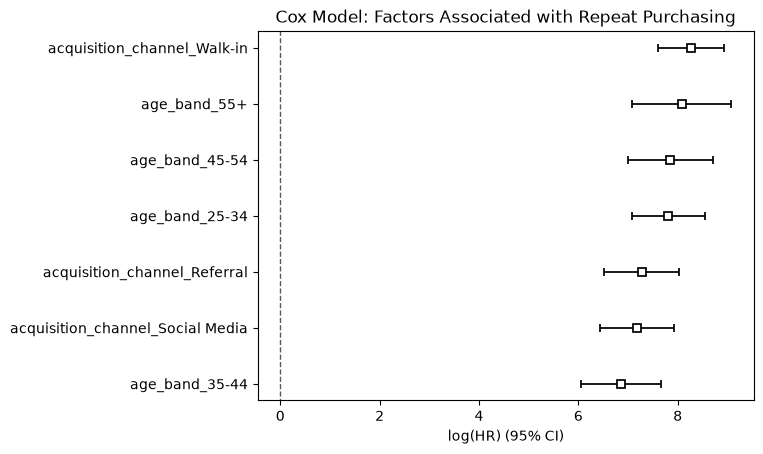

In [239]:

from lifelines import CoxPHFitter
import matplotlib.pyplot as plt

cox_data = survival[["duration", "event", "age_band", "acquisition_channel"]].copy()

cox_data = pd.get_dummies(cox_data, columns=["age_band", "acquisition_channel"], drop_first=True, dtype=int)

cox_data = cox_data.dropna()
cox_data["duration"] = cox_data["duration"].clip(lower=0.01)

cox = CoxPHFitter(penalizer=0.1)
cox.fit(cox_data, duration_col="duration", event_col="event")

# Display results without using print_summary()
print("Cox Proportional Hazards Model Results")
print(cox.summary[["coef", "exp(coef)", "p"]].round(4).to_string())

# Plot the coefficients
cox.plot()
plt.title("Cox Model: Factors Associated with Repeat Purchasing")
plt.show()


In [240]:

purchase_dates = orders.groupby("customer_id")["date"].apply(lambda x: x.sort_values().reset_index(drop=True))

first_dates = orders.groupby("customer_id")["date"].min()
second_dates = orders.groupby("customer_id")["date"].apply(lambda x: x.sort_values().iloc[1] if len(x) > 1 else pd.NaT)

survival = first_dates.rename("first_date").reset_index()
survival["second_date"] = survival["customer_id"].map(second_dates)


In [241]:

# Last date in our dataset
end_date = pd.Timestamp("2026-10-31")

# 1 = customer made a second purchase
# 0 = no second purchase observed
survival["event"] = survival["second_date"].notna().astype(int)

# End at second purchase, or dataset end if no second purchase
survival["end_date"] = survival["second_date"].fillna(end_date)

# Days until second purchase or end of observation
survival["duration"] = (survival["end_date"] - survival["first_date"]).dt.days

print(survival["event"].value_counts())
print(survival[["duration", "event"]].describe())

event
1    11702
0     2730
Name: count, dtype: int64
           duration         event
count  14432.000000  14432.000000
mean     205.491685      0.810837
std      347.357335      0.391652
min        0.000000      0.000000
25%       19.000000      1.000000
50%       60.000000      1.000000
75%      184.000000      1.000000
max     1460.000000      1.000000


In [242]:
survival = survival.drop(columns=["age_band", "acquisition_channel"], errors="ignore")

survival = survival.merge(customers[["customer_id", "age_band", "acquisition_channel"]], on="customer_id", how="left")

print(survival.columns.tolist())

['customer_id', 'first_date', 'second_date', 'event', 'end_date', 'duration', 'age_band', 'acquisition_channel']


In [243]:
cox_data = survival[["duration", "event", "age_band", "acquisition_channel"]].copy()

cox_data = cox_data.dropna()

cox_data = pd.get_dummies(cox_data, columns=["age_band", "acquisition_channel"], drop_first=True, dtype=int)

cox_data["duration"] = cox_data["duration"].clip(lower=0.01)

cox = CoxPHFitter(penalizer=0.1)

cox.fit(cox_data, duration_col="duration", event_col="event")

print(cox.summary.round(3))
print("Concordance:", round(cox.concordance_index_, 3))

                                   coef  exp(coef)  se(coef)  coef lower 95%  \
covariate                                                                      
age_band_25-34                    0.020      1.020     0.022          -0.024   
age_band_35-44                    0.059      1.061     0.025           0.011   
age_band_45-54                    0.058      1.060     0.030           0.000   
age_band_55+                      0.012      1.012     0.039          -0.064   
acquisition_channel_Referral      0.198      1.218     0.034           0.132   
acquisition_channel_Social Media  0.207      1.230     0.033           0.143   
acquisition_channel_Walk-in       0.215      1.240     0.031           0.155   

                                  coef upper 95%  exp(coef) lower 95%  \
covariate                                                               
age_band_25-34                             0.063                0.977   
age_band_35-44                             0.108            

In [244]:
print(survival[["first_date", "second_date", "duration", "event"]].head(10))

print("Zero-day durations:", (survival["duration"] == 0).sum())

  first_date second_date  duration  event
0 2023-08-17  2023-10-25        69      1
1 2023-02-08  2023-05-04        85      1
2 2025-02-18  2025-09-07       201      1
3 2022-11-17  2022-12-08        21      1
4 2025-12-11         NaT       324      0
5 2024-10-16  2024-12-19        64      1
6 2022-11-27  2022-12-19        22      1
7 2023-03-01         NaT      1340      0
8 2025-09-24  2026-01-15       113      1
9 2023-03-20         NaT      1321      0
Zero-day durations: 9


In [245]:
zero_day = survival[survival["duration"] == 0]

print(zero_day[["customer_id", "first_date", "second_date", "event"]])

       customer_id first_date second_date  event
145         108180 2026-10-31         NaT      0
1117        166906 2026-10-31         NaT      0
1508        189878 2026-10-31         NaT      0
1837        210523 2026-10-31         NaT      0
2619        263749 2026-10-31         NaT      0
3165        299545 2026-10-31         NaT      0
7971        598449 2026-10-31         NaT      0
9230        676438 2026-10-31         NaT      0
11635       824668 2026-10-31         NaT      0


In [246]:
# Exclude customers with zero follow-up time
cox_data = cox_data.loc[survival.loc[cox_data.index, "duration"] > 0].copy()

# Refit Cox model
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)

cox.fit(cox_data, duration_col="duration", event_col="event")

# Check proportional hazards assumption
cox.check_assumptions(cox_data, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age_band_25-34' failed the non-proportional test: p-value is 0.0024.

   Advice: with so few unique values (only 2), you can include `strata=['age_band_25-34', ...]` in
the call in `.fit`. See documentation in link [E] below.

2. Variable 'age_band_45-54' failed the non-proportional test: p-value is 0.0066.

   Advice: with so few unique values (only 2), you can include `strata=['age_band_45-54', ...]` in
the call in `.fit`. See documentation in link [E] below.

3. Variable 'acquisition_channel_Referral' failed the non-proportional test: p-value is 0.0020.

   Advice: with so few unique values (only 2), you can include
`strata=['acquisition_channel_Referral', ...]` in the call in `.fit`. See documentation in link [E]
below.

4. Variable 'acquisition_channel_Social Media' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['acquisition_channel_Social
Media', ...]` in the call in `.fit`. See document

[]

In [247]:
cox.check_assumptions(cox_data, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age_band_25-34' failed the non-proportional test: p-value is 0.0024.

   Advice: with so few unique values (only 2), you can include `strata=['age_band_25-34', ...]` in
the call in `.fit`. See documentation in link [E] below.

2. Variable 'age_band_45-54' failed the non-proportional test: p-value is 0.0066.

   Advice: with so few unique values (only 2), you can include `strata=['age_band_45-54', ...]` in
the call in `.fit`. See documentation in link [E] below.

3. Variable 'acquisition_channel_Referral' failed the non-proportional test: p-value is 0.0020.

   Advice: with so few unique values (only 2), you can include
`strata=['acquisition_channel_Referral', ...]` in the call in `.fit`. See documentation in link [E]
below.

4. Variable 'acquisition_channel_Social Media' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['acquisition_channel_Social
Media', ...]` in the call in `.fit`. See document

[]

In [248]:
# Use the original customer characteristics
cox_stratified = survival[["duration", "event", "age_band", "acquisition_channel"]].copy()

# Remove zero-day follow-up and missing values
cox_stratified = cox_stratified[cox_stratified["duration"] > 0].dropna()

# Fit stratified Cox model
cox2 = CoxPHFitter(penalizer=0.1)

cox2.fit(cox_stratified, duration_col="duration", event_col="event", strata=["age_band", "acquisition_channel"])

print("Concordance:", round(cox2.concordance_index_, 3))

Concordance: 0.5


In [249]:
features = ["recency", "frequency", "monetary"]

In [250]:
print(training_data.columns.tolist())

print(training_data.head())

print(training_data.shape)

['customer_id', 'recency', 'frequency', 'monetary', 'repeat_purchase_90d']
   customer_id  recency  frequency  monetary  repeat_purchase_90d
0       100053        1          3     549.2                    0
1       100061       42          6    1100.0                    0
2       100081       23         14    2490.0                    0
3       100154       57         10     996.5                    1
4       100206      306          1     178.0                    0
(105519, 5)


In [251]:
print("Total rows:", len(training_data))

print("Unique customers:", training_data["customer_id"].nunique())

print("Repeated customer IDs:", training_data["customer_id"].duplicated().sum())

print("Most repeated customers:")
print(training_data["customer_id"].value_counts().head())

Total rows: 105519
Unique customers: 13181
Repeated customer IDs: 92338
Most repeated customers:
customer_id
100053    10
705978    10
705469    10
705219    10
705001    10
Name: count, dtype: int64


In [252]:
print("Columns:", training_data.columns.tolist())

print("\nRows per customer:")
print(training_data.groupby("customer_id").size().describe())

print("\nExample customer:")
print(training_data[training_data["customer_id"] == 100053])

Columns: ['customer_id', 'recency', 'frequency', 'monetary', 'repeat_purchase_90d']

Rows per customer:
count    13181.000000
mean         8.005387
std          2.879004
min          1.000000
25%          6.000000
50%         10.000000
75%         10.000000
max         10.000000
dtype: float64

Example customer:
       customer_id  recency  frequency  monetary  repeat_purchase_90d
0           100053        1          3     549.2                    0
7855        100053       92          3     549.2                    0
16226       100053      183          3     549.2                    0
25174       100053      275          3     549.2                    1
34731       100053       82          4     607.2                    1
44941       100053       73          5     645.2                    0
55952       100053      164          5     645.2                    0
67450       100053      256          5     645.2                    0
79556       100053      348          5     645.2        

In [253]:
print("Training data columns:")
print(training_data.columns.tolist())

print("\nExisting train/test variables:")
print([name for name in globals() if name in ["X_train", "X_test", "y_train", "y_test", "train", "test"]])

Training data columns:
['customer_id', 'recency', 'frequency', 'monetary', 'repeat_purchase_90d']

Existing train/test variables:
['X_train', 'y_train', 'X_test', 'y_test']


In [254]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training columns:")
print(X_train.columns.tolist())

print("Testing columns:")
print(X_test.columns.tolist())

Training shape: (105519, 3)
Testing shape: (13875, 3)
Training columns:
['recency', 'frequency', 'monetary']
Testing columns:
['recency', 'frequency', 'monetary']


In [255]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nExact matching feature rows:")
overlap = X_test.merge(X_train.drop_duplicates(), on=["recency", "frequency", "monetary"], how="inner")

print(len(overlap))

print("\nTest labels:")
print(y_test.value_counts())

Training rows: 105519
Testing rows: 13875

Exact matching feature rows:
571

Test labels:
repeat_purchase_90d
0    10842
1     3033
Name: count, dtype: int64


In [256]:
from sklearn.metrics import classification_report, roc_auc_score

log_predictions = log_model.predict(X_test)
log_probabilities = log_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, log_predictions))

print("ROC-AUC:", round(roc_auc_score(y_test, log_probabilities), 3))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93     10842
           1       0.75      0.71      0.73      3033

    accuracy                           0.89     13875
   macro avg       0.83      0.82      0.83     13875
weighted avg       0.88      0.89      0.88     13875

ROC-AUC: 0.945


In [257]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

boost_model = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15, learning_rate=0.1, random_state=42)

boost_model.fit(X_train, y_train)

boost_predictions = boost_model.predict(X_test)
boost_probabilities = boost_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, boost_predictions))

print("Boosting ROC-AUC:", round(roc_auc_score(y_test, boost_probabilities), 3))

              precision    recall  f1-score   support

           0       0.90      0.96      0.93     10842
           1       0.82      0.62      0.71      3033

    accuracy                           0.89     13875
   macro avg       0.86      0.79      0.82     13875
weighted avg       0.88      0.89      0.88     13875

Boosting ROC-AUC: 0.949


In [258]:
importance = pd.DataFrame({"Feature": X_train.columns, "Coefficient": log_model.named_steps["logisticregression"].coef_[0]})

importance["Absolute Importance"] = importance["Coefficient"].abs()

print(importance.sort_values("Absolute Importance", ascending=False))

     Feature  Coefficient  Absolute Importance
0    recency    -3.095359             3.095359
1  frequency     0.289522             0.289522
2   monetary     0.266547             0.266547


In [259]:
print("First purchase:", purchases["date"].min())
print("Last purchase:", purchases["date"].max())

print("Training rows:", len(training_data))
print("Test rows:", len(testing_data))

First purchase: 2022-11-01 00:00:00
Last purchase: 2026-10-31 00:00:00
Training rows: 105519
Test rows: 13875


In [260]:
# 1. Check that we're only analyzing purchases
print("Purchase types:")
print(purchases["row_type"].value_counts())

# 2. Check for missing values
print("\nMissing values:")
print(purchases[["customer_id", "transaction_id", "date", "quantity", "unit_price_paid"]].isna().sum())

# 3. Check for duplicate sales rows
print("\nDuplicate rows:")
print(purchases.duplicated().sum())

# 4. Check for invalid purchase values
print("\nNon-positive quantities:")
print((purchases["quantity"] <= 0).sum())

print("\nNegative prices:")
print((purchases["unit_price_paid"] < 0).sum())

# 5. Check the actual time period
print("\nDate range:")
print(purchases["date"].min())
print(purchases["date"].max())

Purchase types:
row_type
Purchase    323703
Name: count, dtype: int64

Missing values:
customer_id        0
transaction_id     0
date               0
quantity           0
unit_price_paid    0
dtype: int64

Duplicate rows:
934

Non-positive quantities:
0

Negative prices:
0

Date range:
2022-11-01 00:00:00
2026-10-31 00:00:00


In [261]:
duplicates = purchases[purchases.duplicated(keep=False)].copy()

print("Duplicate rows including originals:", len(duplicates))

print("\nExample duplicate records:")
print(duplicates.sort_values(["transaction_id", "customer_id"]).head(20).to_string())

print("\nTransactions affected:")
print(duplicates["transaction_id"].nunique())

Duplicate rows including originals: 1868

Example duplicate records:
     transaction_id       date      time  customer_id item_id  quantity  unit_price_paid  row_type original_transaction_id tier_at_purchase  points_earned  points_redeemed  points_balance_after notes  original_transaction_id_was_missing  tier_at_purchase_was_missing  points_earned_was_missing  points_redeemed_was_missing  points_balance_after_was_missing    month signup_date age_band   home_area acquisition_channel          interests loyalty_join_date  flag_invalid_signup_date  flag_loyalty_before_signup  flag_duplicate_customer_id           item_name            category   activity      season  price  production_cost   cohort purchase_month  cohort_month  revenue
596        T1000351 2022-11-04  11:26:07       913740     H01         1            128.0  Purchase                     NaN              NaN            NaN              NaN                   NaN   NaN                                 True                       

In [262]:
# Number of purchase rows per transaction
transaction_sizes = purchases.groupby("transaction_id").size()

# Number of rows in transactions containing duplicates
affected_ids = duplicates["transaction_id"].unique()

print("Affected transaction sizes:")
print(transaction_sizes.loc[affected_ids].value_counts().sort_index())

# Inspect one complete transaction
print("\nExample complete transaction:")
print(purchases[purchases["transaction_id"] == "T1000351"][["transaction_id", "item_id", "quantity", "unit_price_paid"]].to_string(index=False))

Affected transaction sizes:
2    194
3    341
4    249
5    100
6     29
7     19
8      1
Name: count, dtype: int64

Example complete transaction:
transaction_id item_id  quantity  unit_price_paid
      T1000351     H01         1            128.0
      T1000351     H01         1            128.0


In [263]:
customer_counts = purchases.groupby("transaction_id")["customer_id"].nunique()

print("Transactions linked to multiple customers:", (customer_counts > 1).sum())

print("Total unique transactions:", purchases["transaction_id"].nunique())

Transactions linked to multiple customers: 0
Total unique transactions: 168483


In [265]:

from datetime import datetime, timedelta

print("Training cutoff dates:")
print(training_dates)

print("\nTesting cutoff date:")
print("2026-08-01")

print("\nTraining cutoff dates with overlapping test window:")

test_start = datetime(2026, 8, 1)

for date in training_dates:
    train_end = datetime.fromisoformat(date) + timedelta(days=90)

    if train_end > test_start:
        print(date, "->", train_end.date())


Training cutoff dates:
['2024-01-01', '2024-04-01', '2024-07-01', '2024-10-01', '2025-01-01', '2025-04-01', '2025-07-01', '2025-10-01', '2026-01-01', '2026-04-01']

Testing cutoff date:
2026-08-01

Training cutoff dates with overlapping test window:


In [266]:
from sklearn.metrics import average_precision_score

print("Repeat purchase rate:", round(y_test.mean(), 3))

print("Logistic Regression AP:", round(average_precision_score(y_test, log_probabilities), 3))

print("Gradient Boosting AP:", round(average_precision_score(y_test, boost_probabilities), 3))

Repeat purchase rate: 0.219
Logistic Regression AP: 0.825
Gradient Boosting AP: 0.846


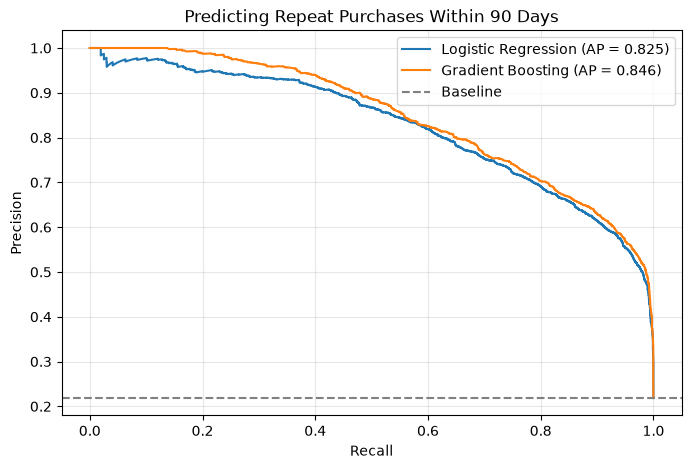

In [267]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

p1, r1, _ = precision_recall_curve(y_test, log_probabilities)
p2, r2, _ = precision_recall_curve(y_test, boost_probabilities)

plt.figure(figsize=(8, 5))

plt.plot(r1, p1, label="Logistic Regression (AP = 0.825)")
plt.plot(r2, p2, label="Gradient Boosting (AP = 0.846)")

plt.axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Predicting Repeat Purchases Within 90 Days")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [268]:
results = X_test.copy()

results["actual"] = y_test.to_numpy()
results["predicted_probability"] = boost_probabilities

results["recency_group"] = pd.cut(results["recency"], bins=[-1, 30, 90, 180, float("inf")], labels=["0-30 days", "31-90 days", "91-180 days", "180+ days"])

summary = results.groupby("recency_group", observed=True).agg(customers=("actual", "size"), actual_repeat_rate=("actual", "mean"), predicted_repeat_rate=("predicted_probability", "mean"))

print(summary.round(3))

               customers  actual_repeat_rate  predicted_repeat_rate
recency_group                                                      
0-30 days           2002               0.795                  0.778
31-90 days          1519               0.558                  0.508
91-180 days          952               0.342                  0.282
180+ days           9402               0.029                  0.024


In [269]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

recency_model = LogisticRegression(max_iter=1000)

recency_model.fit(X_train[["recency"]], y_train)

recency_prob = recency_model.predict_proba(X_test[["recency"]])[:, 1]

print("Recency-only ROC-AUC:", round(roc_auc_score(y_test, recency_prob), 3))

print("Recency-only AP:", round(average_precision_score(y_test, recency_prob), 3))

Recency-only ROC-AUC: 0.94
Recency-only AP: 0.767


In [270]:
print("Training dates:", training_dates)
print("Testing date: 2026-08-01")

print("\nTraining customers:", training_data["customer_id"].nunique())

print("Testing customers:", testing_data["customer_id"].nunique())

shared = set(training_data["customer_id"]) & set(testing_data["customer_id"])

print("Customers appearing in both:", len(shared))

Training dates: ['2024-01-01', '2024-04-01', '2024-07-01', '2024-10-01', '2025-01-01', '2025-04-01', '2025-07-01', '2025-10-01', '2026-01-01', '2026-04-01']
Testing date: 2026-08-01

Training customers: 13181
Testing customers: 13875
Customers appearing in both: 13181


In [271]:
past = purchases[purchases["date"] < cutoff].copy()

In [272]:
print("Purchase date range:")
print(purchases["date"].min())
print(purchases["date"].max())

print("\nTest cutoff:")
print(pd.Timestamp("2026-08-01"))

print("\nCustomers with test features:")
print(len(testing_data))

Purchase date range:
2022-11-01 00:00:00
2026-10-31 00:00:00

Test cutoff:
2026-08-01 00:00:00

Customers with test features:
13875


In [273]:
cutoff = pd.Timestamp("2026-08-01")

past = purchases[purchases["date"] < cutoff].copy()

last_purchase = past.groupby("customer_id")["date"].max()

check = testing_data[["customer_id", "recency"]].copy()

check["actual_last_purchase"] = check["customer_id"].map(last_purchase)

check["expected_recency"] = (cutoff - check["actual_last_purchase"]).dt.days

print("Recency mismatches:")
print((check["recency"] != check["expected_recency"]).sum())

print("\nFuture dates in feature history:")
print((past["date"] >= cutoff).sum())

Recency mismatches:
0

Future dates in feature history:
0


In [274]:
past["revenue"] = past["quantity"] * past["unit_price_paid"]

expected = past.groupby("customer_id").agg(expected_frequency=("transaction_id", "nunique"), expected_monetary=("revenue", "sum"))

check = testing_data.merge(expected, on="customer_id", how="left")

print("Frequency mismatches:")
print((check["frequency"] != check["expected_frequency"]).sum())

print("\nMonetary mismatches:")
print(((check["monetary"] - check["expected_monetary"]).abs() > 0.01).sum())

Frequency mismatches:
0

Monetary mismatches:
0


In [275]:
customer_targets = testing_data.copy()

customer_targets["purchase_probability"] = boost_probabilities

customer_targets["value_group"] = pd.qcut(customer_targets["monetary"], q=4, labels=["Low", "Medium", "High", "Very High"], duplicates="drop")

print(customer_targets.head(10))

   customer_id  recency  frequency  monetary  repeat_purchase_90d  \
0       100053      560          5     645.2                    0   
1       100061      985          6    1100.0                    0   
2       100073      305          3     218.0                    0   
3       100081      742         17    3086.0                    0   
4       100090      233          1     844.0                    0   
5       100126      340          6    1024.0                    0   
6       100154      653         18    2198.5                    0   
7       100206     1249          1     178.0                    0   
8       100249      198          2     990.0                    0   
9       100279     1230          1      98.0                    0   

   purchase_probability value_group  
0              0.010400      Medium  
1              0.000167        High  
2              0.070952         Low  
3              0.000893   Very High  
4              0.228829        High  
5           

In [276]:
import numpy as np

high_value = customer_targets["value_group"].isin(["High", "Very High"])

likely_return = customer_targets["purchase_probability"] >= 0.5

customer_targets["segment"] = np.select([high_value & likely_return, high_value & ~likely_return, ~high_value & likely_return, ~high_value & ~likely_return], [
        "High-Value Active",
        "High-Value At Risk",
        "Growing Customers",
        "Low-Priority Customers"], default="Other")

print(customer_targets["segment"].value_counts())

segment
Low-Priority Customers    6821
High-Value At Risk        4747
High-Value Active         2185
Growing Customers          122
Name: count, dtype: int64


In [277]:
segment_summary = customer_targets.groupby("segment").agg(
    customers=("customer_id", "nunique"),
    total_spending=("monetary", "sum"),
    average_spending=("monetary", "mean"),
    average_recency=("recency", "mean"),
    average_purchase_probability=("purchase_probability", "mean"))

segment_summary["spending_share_%"] = (
    segment_summary["total_spending"]
    / segment_summary["total_spending"].sum()
    * 100)

print(segment_summary.round(2).to_string())

                        customers  total_spending  average_spending  average_recency  average_purchase_probability  spending_share_%
segment                                                                                                                             
Growing Customers             122         54772.6            448.96             8.70                          0.55              0.21
High-Value Active            2185      13340531.6           6105.51            23.78                          0.81             51.64
High-Value At Risk           4747      10457224.1           2202.91           592.39                          0.08             40.48
Low-Priority Customers       6821       1982356.1            290.63           668.79                          0.09              7.67


In [278]:
at_risk = customer_targets[customer_targets["segment"] == "High-Value At Risk"].copy()

at_risk["recency_group"] = pd.cut(
    at_risk["recency"],
    bins=[0, 90, 180, 365, float("inf")],
    labels=["0-90 days", "91-180 days",
            "181-365 days", "365+ days"],
    include_lowest=True)

summary = at_risk.groupby("recency_group", observed=True).agg(customers=("customer_id", "count"), historical_spending=("monetary", "sum"))

print(summary.round(2))

               customers  historical_spending
recency_group                                
0-90 days            316             573418.0
91-180 days          471            1207995.5
181-365 days         802            1937310.3
365+ days           3158            6738500.3


In [279]:
# Add customer demographics to the test dataset
age_analysis = testing_data.merge(customers[["customer_id", "age_band"]], on="customer_id", how="left")

# Calculate repeat-purchase rates by age
age_retention = age_analysis.groupby("age_band").agg(customers=("customer_id", "nunique"), repeat_rate=("repeat_purchase_90d", "mean"))

age_retention["repeat_rate"] *= 100

print(age_retention.round(2))

          customers  repeat_rate
age_band                        
18-24          2867        13.67
25-34          5043        22.88
35-44          3167        25.07
45-54          1694        24.56
55+             837        25.09


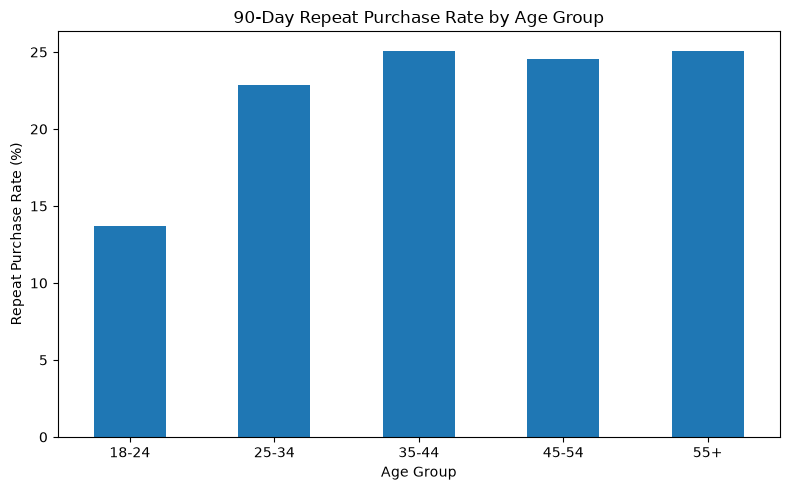

In [280]:
import matplotlib.pyplot as plt

age_retention["repeat_rate"].plot(kind="bar", figsize=(8, 5))

plt.title("90-Day Repeat Purchase Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Repeat Purchase Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [281]:
channel_analysis = testing_data.merge(customers[["customer_id", "acquisition_channel"]], on="customer_id", how="left")

channel_retention = channel_analysis.groupby("acquisition_channel").agg(customers=("customer_id", "nunique"), repeat_rate=("repeat_purchase_90d", "mean"))

channel_retention["repeat_rate"] *= 100

print(channel_retention.round(2))

                     customers  repeat_rate
acquisition_channel                        
Pilates Campaign           360         7.78
Referral                  2799        22.08
Social Media              3395        22.56
Walk-in                   7321        22.14


In [282]:
import statsmodels.formula.api as smf
import numpy as np

# Combine demographics with purchasing history
analysis = testing_data.merge(
    customers[["customer_id", "age_band", "acquisition_channel"]],
    on="customer_id",
    how="left",
    validate="one_to_one")

# Fit an explanatory logistic regression
model = smf.logit(
    formula="""
    repeat_purchase_90d ~
    np.log1p(recency) +
    np.log1p(frequency) +
    np.log1p(monetary) +
    C(age_band) +
    C(acquisition_channel)
    """,
    data=analysis).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.260729
         Iterations 7
                            Logit Regression Results                           
Dep. Variable:     repeat_purchase_90d   No. Observations:                13608
Model:                           Logit   Df Residuals:                    13597
Method:                            MLE   Df Model:                           10
Date:                 Sun, 22 Nov 2026   Pseudo R-squ.:                  0.5027
Time:                         16:17:58   Log-Likelihood:                -3548.0
converged:                        True   LL-Null:                       -7134.9
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                  3

In [283]:
import statsmodels.formula.api as smf
import numpy as np

print("Statsmodels is ready!")

Statsmodels is ready!


In [284]:
import statsmodels.formula.api as smf
import numpy as np

analysis = testing_data.merge(
    customers[["customer_id", "age_band", "acquisition_channel"]],
    on="customer_id",
    how="left",
    validate="one_to_one")

model = smf.logit(
    formula="""
    repeat_purchase_90d ~
    np.log1p(recency) +
    np.log1p(frequency) +
    np.log1p(monetary) +
    C(age_band) +
    C(acquisition_channel)
    """,
    data=analysis).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.260729
         Iterations 7
                            Logit Regression Results                           
Dep. Variable:     repeat_purchase_90d   No. Observations:                13608
Model:                           Logit   Df Residuals:                    13597
Method:                            MLE   Df Model:                           10
Date:                 Sun, 22 Nov 2026   Pseudo R-squ.:                  0.5027
Time:                         16:18:00   Log-Likelihood:                -3548.0
converged:                        True   LL-Null:                       -7134.9
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                  3

In [285]:
# Test whether acquisition channel matters overall
channel_test = model.wald_test(
    "C(acquisition_channel)[T.Referral] = 0, "
    "C(acquisition_channel)[T.Social Media] = 0, "
    "C(acquisition_channel)[T.Walk-in] = 0")

print(channel_test)

<Wald test (chi2): statistic=2.596894977219984, p-value=0.45803415752786636, df_denom=3>


In [286]:
age_test = model.wald_test(
    "C(age_band)[T.25-34] = 0, "
    "C(age_band)[T.35-44] = 0, "
    "C(age_band)[T.45-54] = 0, "
    "C(age_band)[T.55+] = 0")

print(age_test)

<Wald test (chi2): statistic=28.420111735197, p-value=1.0251371174029318e-05, df_denom=4>
